# Diabetes

Objectif : prédire si un patient est **diabétique ou prédiabétique (1)** ou non **(0)** à partir de 21 features (tension, cholestérol, IMC, activité physique, âge, revenu…).

Ce notebook couvre :
1. l'import des données,
2. le nettoyage et le prétraitement (valeurs manquantes, doublons, centrage-réduction, ACP),
3. la séparation train / test.
4. l'entraînement du jeu de données avec sélection de features
5. la validation et la comparaison des modèles

Toutes les fonctions utilisées sont dans `ml_workflow.py`.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA

import ml_workflow as mw

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)

# Listes de colonnes propres à Diabetes

# - features binaires (0 = non, 1 = oui) :
DIABETE_BINARY = ["HighBP", "HighChol", "CholCheck", "Smoker", "Stroke", "HeartDiseaseorAttack",
          "PhysActivity", "Fruits", "Veggies", "HvyAlcoholConsump", "AnyHealthcare",
          "NoDocbcCost", "DiffWalk", "Sex"]

# - features ordinales (catégories dont l'ordre a un sens) : 
DIABETE_ORDINAL = ["GenHlth", "Age", "Education", "Income"]

# - features numériques : 
DIABETE_NUMERIC = ["BMI", "MentHlth", "PhysHlth"]

## 1. Import des données

Le fichier `diabetes_binary_health_indicators_BRFSS2015.csv` a un en-tête.
La première colonne, `Diabetes_binary`, est la cible.

In [3]:
X, y = mw.load_diabetes()
print(X.shape, y.shape)
X.head()

(253680, 21) (253680,)


,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,Veggies,HvyAlcoholConsump,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,1.0,1.0,1.0,40.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,5.0,18.0,15.0,1.0,0.0,9.0,4.0,3.0
1,0.0,0.0,0.0,25.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,3.0,0.0,0.0,0.0,0.0,7.0,6.0,1.0
2,1.0,1.0,1.0,28.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,5.0,30.0,30.0,1.0,0.0,9.0,4.0,8.0
3,1.0,0.0,1.0,27.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0,1.0,0.0,2.0,0.0,0.0,0.0,0.0,11.0,3.0,6.0
4,1.0,1.0,1.0,24.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0,1.0,0.0,2.0,3.0,0.0,0.0,0.0,11.0,5.0,4.0


In [4]:
mw.describe_dataset(X, y)

{'n_samples': 253680,
 'n_features': 21,
 'n_missing': 0,
 'n_duplicates': 24206,
 'class_ratio': {0: 0.861, 1: 0.139}}

### Répartition des classes

Environ 14 % de positifs : le dataset est **déséquilibré**, donc l'accuracy est trompeuse. 
- On comparera les modèles et on choisira une métrique adaptée (voir la partie 4). 
- On pondérera les classes quand le modèle le permet, et on stratifiera le split pour conserver cette proportion.

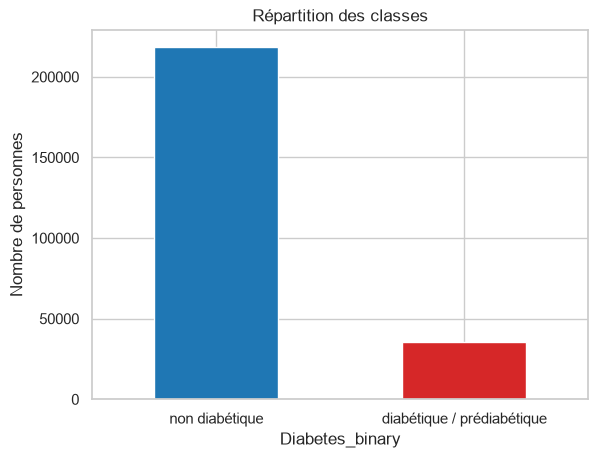

In [5]:
ax = y.value_counts().rename({0: "non diabétique", 1: "diabétique / prédiabétique"}).plot.bar(
    color=["tab:blue", "tab:red"])
ax.set_title("Répartition des classes")
ax.set_ylabel("Nombre de personnes")
plt.xticks(rotation=0)
plt.show()

### Types de features

Les features sont de trois types :
- **14 binaires** (0 ou 1) : hypertension, cholestérol, tabac, AVC, activité physique…
- **4 ordinales** : état de santé général (1 = excellent → 5 = mauvais), tranche d'âge (1 → 13), niveau d'études (1 → 6), revenu (1 → 8). Leur ordre a un sens, on les garde donc telles quelles.
- **3 numériques** : l'IMC et le nombre de jours de mauvaise santé mentale / physique sur les 30 derniers jours.

In [6]:
pd.DataFrame({"type": ["binaire"] * len(DIABETE_BINARY) + ["ordinale"] * len(DIABETE_ORDINAL) + ["numérique"] * len(DIABETE_NUMERIC),
              "nb valeurs distinctes": X[DIABETE_BINARY + DIABETE_ORDINAL + DIABETE_NUMERIC].nunique().values},
              index=DIABETE_BINARY + DIABETE_ORDINAL + DIABETE_NUMERIC).T

,HighBP,HighChol,CholCheck,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,Veggies,HvyAlcoholConsump,AnyHealthcare,NoDocbcCost,DiffWalk,Sex,GenHlth,Age,Education,Income,BMI,MentHlth,PhysHlth
type,binaire,binaire,binaire,binaire,binaire,binaire,binaire,binaire,binaire,binaire,binaire,binaire,binaire,binaire,ordinale,ordinale,ordinale,ordinale,numérique,numérique,numérique
nb valeurs distinctes,2,2,2,2,2,2,2,2,2,2,2,2,2,2,5,13,6,8,84,31,31


In [7]:
X[DIABETE_ORDINAL + DIABETE_NUMERIC].describe().T

,count,mean,std,min,25%,50%,75%,max
GenHlth,253680.0,2.511392,1.068477,1.0,2.0,2.0,3.0,5.0
Age,253680.0,8.032119,3.054220,1.0,6.0,8.0,10.0,13.0
Education,253680.0,5.050434,0.985774,1.0,4.0,5.0,6.0,6.0
Income,253680.0,6.053875,2.071148,1.0,5.0,7.0,8.0,8.0
BMI,253680.0,28.382364,6.608694,12.0,24.0,27.0,31.0,98.0
MentHlth,253680.0,3.184772,7.412847,0.0,0.0,0.0,2.0,30.0
PhysHlth,253680.0,4.242081,8.717951,0.0,0.0,0.0,3.0,30.0


### Features numériques

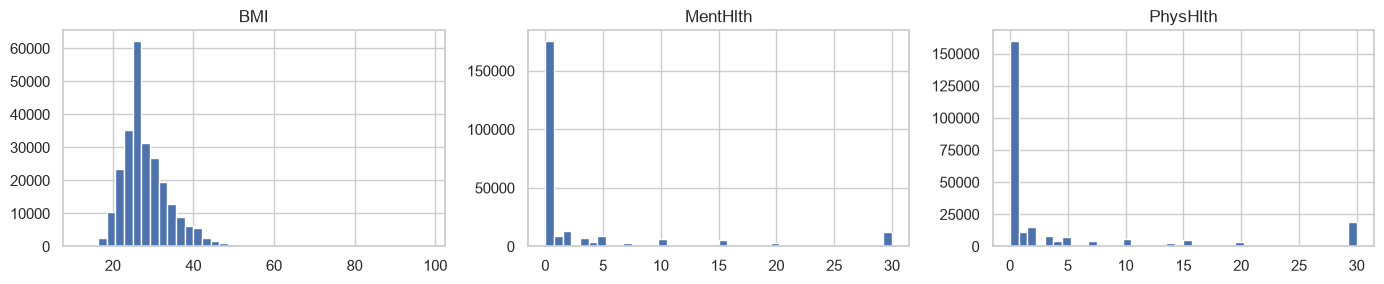

BMI standardisé : max z = 10.5
Part de 0 : MentHlth 69%, PhysHlth 63%


In [8]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3))
for ax, col in zip(axes, DIABETE_NUMERIC):
    ax.hist(X[col], bins=40)
    ax.set_title(col)
plt.tight_layout()
plt.show()

z_bmi = (X["BMI"] - X["BMI"].mean()) / X["BMI"].std()
print(f"BMI standardisé : max z = {z_bmi.max():.1f}")
print(f"Part de 0 : MentHlth {(X['MentHlth'] == 0).mean():.0%}, PhysHlth {(X['PhysHlth'] == 0).mean():.0%}")

`MentHlth` et `PhysHlth` valent 0 pour la majorité des personnes (69 % et 63 %). L'IMC est légèrement asymétrique, avec quelques valeurs très élevées (jusqu'à 98, soit z ≈ 10 après standardisation), mais elles sont rares et restent plausibles. 
On ne fait donc pas de transformation $\log(1+x)$ : la standardisation suffit.

### Corrélation avec la cible

Première idée des features utiles (corrélation linéaire seulement, la sélection de features sera faite proprement plus tard).

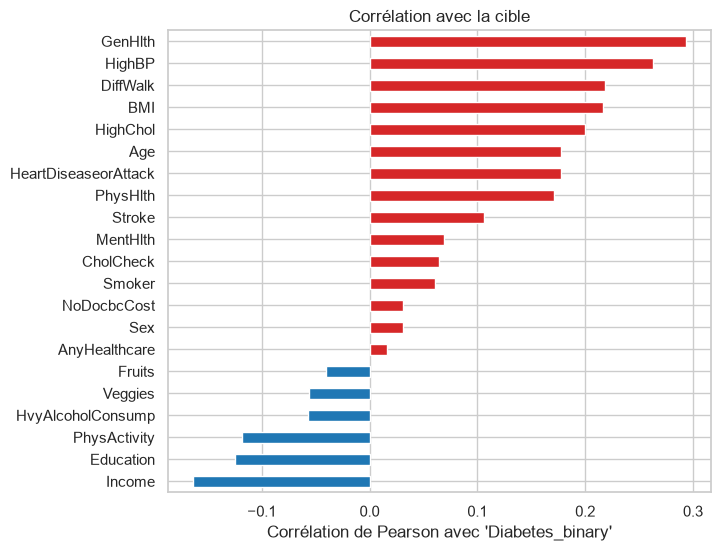

In [9]:
corr = X.corrwith(y).sort_values()
corr.plot.barh(figsize=(7, 6), color=["tab:red" if v > 0 else "tab:blue" for v in corr])
plt.title("Corrélation avec la cible")
plt.xlabel("Corrélation de Pearson avec 'Diabetes_binary'")
plt.show()

- Les plus liées positivement au diabète sont l'état de santé général (`GenHlth`), l'hypertension (`HighBP`), les difficultés à marcher (`DiffWalk`), l'IMC (`BMI`) et le cholestérol.

- Le revenu (`Income`), le niveau d'études (`Education`) et l'activité physique (`PhysActivity`) sont liés négativement.

## 2. Nettoyage

### Valeurs manquantes

La documentation annonce aucune valeur manquante, on le vérifie. La fonction `mw.preprocess` contient tout de même une étape d'imputation (moyenne du train), pour que le workflow reste générique.

In [10]:
print("Valeurs manquantes :", X.isna().sum().sum())

Valeurs manquantes : 0


### Doublons

Environ 24 000 lignes sont des doublons exacts (mêmes réponses et même label). On les supprime **avant le split** : sinon une même ligne pourrait se retrouver à la fois dans le train et dans le test, ce qui surestimerait les performances.

In [11]:
n_before = len(X)
X_clean, y_clean = mw.remove_duplicates(X, y)
print(f"{n_before - len(X_clean)} doublons supprimés -> {len(X_clean)} personnes")
print("Part de positifs après nettoyage :", round(y_clean.mean(), 3))

24206 doublons supprimés -> 229474 personnes
Part de positifs après nettoyage : 0.153


In [12]:
X_clean[DIABETE_NUMERIC].describe().T

,count,mean,std,min,25%,50%,75%,max
BMI,229474.0,28.687507,6.789204,12.0,24.0,27.0,32.0,98.0
MentHlth,229474.0,3.509866,7.717643,0.0,0.0,0.0,2.0,30.0
PhysHlth,229474.0,4.681219,9.050877,0.0,0.0,0.0,4.0,30.0


## 3. Séparation train / test

Split **stratifié** 80 / 20 : le test set ne sera utilisé qu'à la toute fin, pour évaluer le modèle retenu. Le choix des hyperparamètres et des features se fera par validation croisée sur le train.

In [13]:
X_train, X_test, y_train, y_test = mw.split_data(X_clean, y_clean, test_size=0.2,
                                                 random_state=RANDOM_STATE)
print("Train :", X_train.shape, "| part de positifs :", round(y_train.mean(), 3))
print("Test  :", X_test.shape, "| part de positifs :", round(y_test.mean(), 3))

Train : (183579, 21) | part de positifs : 0.153
Test  : (45895, 21) | part de positifs : 0.153


### Centrage-réduction

Ajusté sur le train uniquement, puis appliqué au test :

$$
z_{ij} = \frac{x_{ij} - \mu_j^{\text{train}}}{\sigma_j^{\text{train}}}
$$

Sur le train, chaque feature a donc une moyenne de 0 et un écart-type de 1 ; sur le test, c'est seulement approximatif, ce qui est normal.

In [14]:
X_train_s, X_test_s, tr = mw.preprocess(X_train, X_test, impute_strategy="mean", scale=True)
pd.DataFrame({
    "moyenne train": X_train_s.mean().round(3),
    "écart-type train": X_train_s.std(ddof=0).round(3),
    "moyenne test": X_test_s.mean().round(3),
    "écart-type test": X_test_s.std(ddof=0).round(3),
}).head(8)

,moyenne train,écart-type train,moyenne test,écart-type test
HighBP,0.0,1.0,0.002,1.000
HighChol,0.0,1.0,0.001,1.000
CholCheck,0.0,1.0,-0.003,1.007
BMI,-0.0,1.0,0.008,1.016
Smoker,-0.0,1.0,0.005,1.000
Stroke,-0.0,1.0,0.008,1.018
HeartDiseaseorAttack,0.0,1.0,0.006,1.008
PhysActivity,-0.0,1.0,-0.011,1.006


### ACP

On étudie la variance expliquée par les composantes principales (ACP ajustée sur le train standardisé). Si peu de composantes suffisaient, l'ACP serait une bonne réduction de dimension.

80% de variance expliquée -> 14 composantes sur 21
90% de variance expliquée -> 17 composantes sur 21
95% de variance expliquée -> 19 composantes sur 21


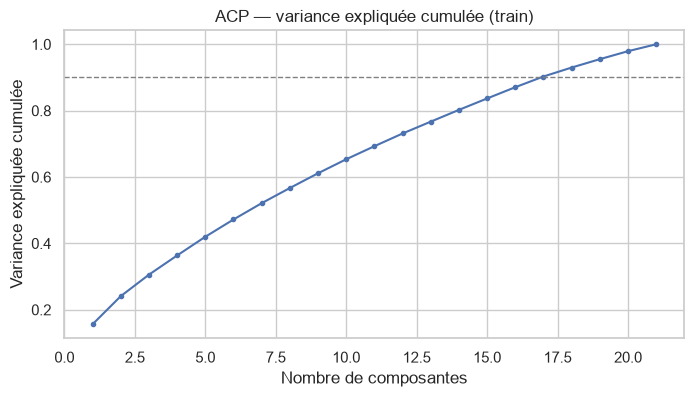

In [15]:
pca_full = PCA(random_state=RANDOM_STATE).fit(X_train_s)
cum_var = np.cumsum(pca_full.explained_variance_ratio_)

for seuil in (0.8, 0.9, 0.95):
    k = int(np.searchsorted(cum_var, seuil) + 1)
    print(f"{seuil:.0%} de variance expliquée -> {k} composantes sur {X_train_s.shape[1]}")

plt.figure(figsize=(8, 4))
plt.plot(range(1, len(cum_var) + 1), cum_var, marker=".")
plt.axhline(0.9, color="grey", ls="--", lw=1)
plt.xlabel("Nombre de composantes")
plt.ylabel("Variance expliquée cumulée")
plt.title("ACP — variance expliquée cumulée (train)")
plt.show()

Il faut 17 composantes sur 21 pour garder 90 % de la variance : les features sont peu corrélées entre elles et l'ACP compresse peu.

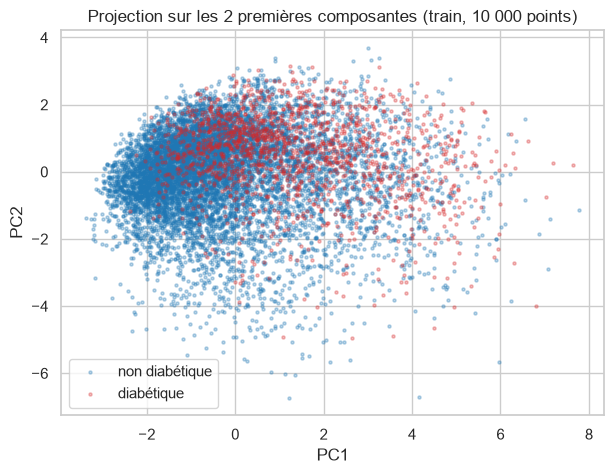

In [16]:
pcs = PCA(n_components=2, random_state=RANDOM_STATE).fit_transform(X_train_s)
rng = np.random.default_rng(RANDOM_STATE)
idx = rng.choice(len(pcs), 10000, replace=False)  # 10 000 points pour garder un graphe lisible
plt.figure(figsize=(7, 5))
for label, name, c in [(0, "non diabétique", "tab:blue"), (1, "diabétique", "tab:red")]:
    m = (y_train.to_numpy()[idx] == label)
    plt.scatter(pcs[idx][m, 0], pcs[idx][m, 1], s=5, alpha=0.3, c=c, label=name)
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("Projection sur les 2 premières composantes (train, 10 000 points)")
plt.legend()
plt.show()

Les diabétiques sont plutôt situés vers les PC1 élevées, mais les deux classes se chevauchent fortement : le problème est intrinsèquement difficile (21 réponses à un questionnaire ne suffisent pas à poser un diagnostic). On testera quand même la variante ACP 90 %.

## Jeux de données prêts pour la suite

`mw.prepare_data` refait les étapes 1 à 3 en une ligne. On prépare les variantes à comparer lors de l'entraînement :
- **full** : les 21 features, standardisées ;
- **ACP 90%** : composantes principales expliquant 90 % de la variance.

In [17]:
datasets = {
    "full": mw.prepare_data("diabetes", random_state=RANDOM_STATE),
    "acp90": mw.prepare_data("diabetes", pca_components=0.9, random_state=RANDOM_STATE),
}

for name, (Xtr, Xte, ytr, yte, _) in datasets.items():
    print(f"{name:6s} train {Xtr.shape}  test {Xte.shape}")

full   train (183579, 21)  test (45895, 21)
acp90  train (183579, 17)  test (45895, 17)


**Bilan des étapes 1 à 3**

- 253 680 personnes, 21 features (14 binaires, 4 ordinales, 3 numériques), **aucune valeur manquante**, 24 206 doublons supprimés.
- Classes **déséquilibrées** (~15 % de positifs après nettoyage) → split stratifié, pondération des classes, métrique adaptée à choisir (l'accuracy est trompeuse).
- Échelles différentes (IMC, âge vs binaires) → centrage-réduction.
- L'ACP compresse peu (environ 17 composantes pour 90 % de la variance) et les classes se chevauchent : elle sera testée mais ce n'est probablement pas la meilleure réduction.

## 4. Entraînement

### Taille des données

Le train fait environ 184 000 lignes. Faire toutes les validations croisées dessus serait très long (surtout pour le k-NN, qui compare chaque point à tout le train, et pour le Random Forest). 

On fait donc les **réglages et la comparaison par validation croisée sur un sous-échantillon stratifié de 30 000 lignes du train**, puis on **réentraîne les modèles retenus sur tout le train** avant l'évaluation finale sur le test.

In [18]:
Xtr, Xte, ytr, yte, _ = datasets["full"]

# Sous-échantillon stratifié du train pour les validations croisées
_, X_cv, _, y_cv = mw.split_data(Xtr, ytr, test_size=30000, random_state=RANDOM_STATE)
print("Sous-échantillon :", X_cv.shape, "| part de positifs :", round(y_cv.mean(), 3))

Sous-échantillon : (30000, 21) | part de positifs : 0.153


### k-NN : choix de k

Le k-NN n'accepte pas de pondération des classes : avec 85 % de négatifs, la majorité des voisins sont presque toujours négatifs. On choisit k par validation croisée (accuracy, critère utilisé par `mw.choose_k_knn`).

k = 71


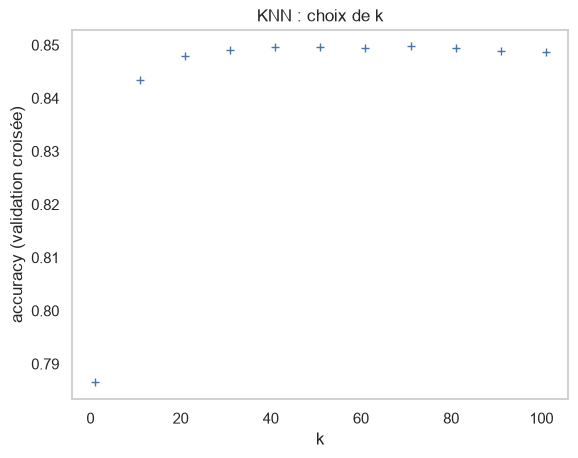

In [19]:
best_k, ks, scores = mw.choose_k_knn(X_cv, y_cv, list(range(1, 102, 10)))
print("k =", best_k)

plt.plot(ks, scores, "+")
plt.xlabel("k")
plt.ylabel("accuracy (validation croisée)")
plt.title("KNN : choix de k")
plt.grid()
plt.show()

### Réseau de neurones : choix du learning rate

On redécoupe le sous-échantillon en train + validation (le test n'est pas touché).

lr=0.01 : loss train 0.357, validation 0.360
lr=0.1 : loss train 0.335, validation 0.345
lr=0.5 : loss train 0.325, validation 0.348


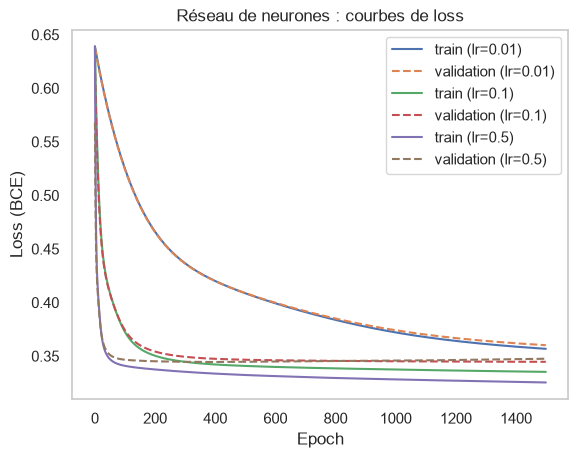

In [20]:
X_fit, X_val, y_fit, y_val = mw.split_data(X_cv, y_cv, 0.2, RANDOM_STATE)

for lr in [0.01, 0.1, 0.5]:
    model, losses, val_losses = mw.train_mlp(X_fit, y_fit, 32, 16, 1500, lr, X_val, y_val)
    plt.plot(losses, label=f"train (lr={lr})")
    plt.plot(val_losses, "--", label=f"validation (lr={lr})")
    print(f"lr={lr} : loss train {losses[-1]:.3f}, validation {val_losses[-1]:.3f}")

plt.xlabel("Epoch")
plt.ylabel("Loss (BCE)")
plt.title("Réseau de neurones : courbes de loss")
plt.legend()
plt.grid()
plt.show()

### Sélection de features

Pour chaque modèle, on cherche le nombre de features à garder . 

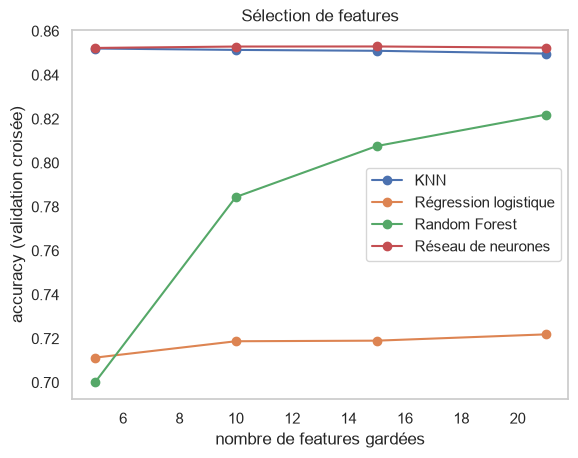

{'KNN': 5,
 'Régression logistique': 21,
 'Random Forest': 21,
 'Réseau de neurones': 15}

In [21]:
models = mw.get_models(best_k, "balanced")  # "balanced" car dataset déséquilibré

n_values = [5, 10, 15, Xtr.shape[1]]
best_n = {}
for name, model in models.items():
    n, ns, sc = mw.choose_n_features(model, X_cv, y_cv, n_values)
    best_n[name] = n
    plt.plot(ns, sc, "o-", label=name)

plt.xlabel("nombre de features gardées")
plt.ylabel("accuracy (validation croisée)")
plt.title("Sélection de features")
plt.legend()
plt.grid()
plt.show()
best_n

La sélection de features apporte peu ici : avec seulement 21 features, la régression logistique et le Random Forest les gardent toutes. Le k-NN n'en garde que 5 (moins de dimensions = distances plus pertinentes), le réseau de neurones 15.

## 5. Validation et comparaison

### Comparaison par validation croisée (sous-échantillon du train)

C'est ici qu'on choisit le modèle. Le test n'est pas utilisé.

In [22]:
final_models = {}
for name, model in models.items():
    final_models[name] = mw.with_feature_selection(model, best_n[name])

cv_results = mw.compare_models(final_models, X_cv, y_cv)
cv_results.round(3)

,accuracy,précision,rappel
KNN,0.852,0.567,0.140
Régression logistique,0.722,0.324,0.752
Random Forest,0.822,0.419,0.427
Réseau de neurones,0.853,0.570,0.162


Chaque métrique désigne un meilleur modèle différent :
- **accuracy** : le réseau de neurones et le k-NN (≈ 85 %), mais répondre toujours « non diabétique » donne déjà 84,7 % ;
- **précision** : le réseau de neurones (57 %), mais il rate plus de 80 % des diabétiques ;
- **rappel** : la régression logistique (75 %), mais signaler tout le monde donnerait 100 %.

Aucune des trois métriques ne suffit seule : la précision et le rappel évoluent en sens inverse (la régression logistique gagne en rappel ce qu'elle perd en précision, le réseau de neurones l'inverse), il faut un critère qui combine les deux.

### Critères qui combinent précision et rappel

- **F1** : moyenne harmonique de la précision et du rappel, qui ont le même poids.
- **Fβ** : même idée, mais le rappel compte β fois plus que la précision (β > 1), ou moins (β < 1).
- **Précision moyenne** (aire sous la courbe précision-rappel) : évalue le modèle sur tous les seuils de décision. Elle nécessite des probabilités en sortie, que notre réseau de neurones ne fournit pas.

In [23]:
cv_results = mw.add_fbeta(cv_results, beta=1)
cv_results = mw.add_fbeta(cv_results, beta=2)
cv_results.round(3)

,accuracy,précision,rappel,F1,F2
KNN,0.852,0.567,0.140,0.225,0.165
Régression logistique,0.722,0.324,0.752,0.453,0.595
Random Forest,0.822,0.419,0.427,0.423,0.426
Réseau de neurones,0.853,0.570,0.162,0.253,0.189


Les deux critères désignent la **régression logistique** (F1 ≈ 0,45, F2 ≈ 0,60), grâce à son rappel élevé (≈ 75 %). Ils ne départagent pourtant pas les modèles de la même façon :
- avec le **F1**, le Random Forest est presque à égalité (0,42) : précision et rappel comptant autant, sa meilleure précision compense son rappel plus faible ;
- avec le **F2**, l'écart se creuse (0,43) : le rappel comptant davantage, le Random Forest est pénalisé de rater plus de la moitié des diabétiques.

Le k-NN et le réseau de neurones, malgré la meilleure accuracy, font moins bien que de signaler tout le monde sur les deux critères : ils ratent la grande majorité des diabétiques.

On retient le **F2**, plus adapté au dépistage puisqu'il pénalise davantage les diabétiques ratés. Seule la régression logistique dépasse le score obtenu en signalant tout le monde (0,47).

$$
F_2 = \frac{(1+2^2) \cdot \text{précision} \cdot \text{rappel}}{2^2 \cdot \text{précision} + \text{rappel}} = \frac{5 \cdot \text{précision} \cdot \text{rappel}}{4 \cdot \text{précision} + \text{rappel}}
$$

### Évaluation finale sur le test

Les modèles sont réentraînés sur **tout le train** (≈ 184 000 lignes), puis évalués une seule fois sur le test.

In [24]:
test_results = {}
for name, model in final_models.items():
    model.fit(Xtr, ytr)
    test_results[name] = mw.evaluate_on_test(model, Xte, yte)

test_df = mw.add_fbeta(pd.DataFrame(test_results).T)
test_df = test_df[["accuracy", "précision", "rappel", "F2", "faux positifs", "faux négatifs"]]
test_df.round(3)

,accuracy,précision,rappel,F2,faux positifs,faux négatifs
KNN,0.853,0.580,0.132,0.156,670.0,6094.0
Régression logistique,0.714,0.318,0.760,0.595,11428.0,1684.0
Random Forest,0.811,0.396,0.443,0.433,4746.0,3910.0
Réseau de neurones,0.854,0.586,0.145,0.170,717.0,6003.0
